<a href="https://colab.research.google.com/github/kpate18/ECGR-4105/blob/main/homework%205/Problem_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


First five rows:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset Shape: (545, 13)

Features:
['area', 'bedrooms', 'bathrooms', 'stories',

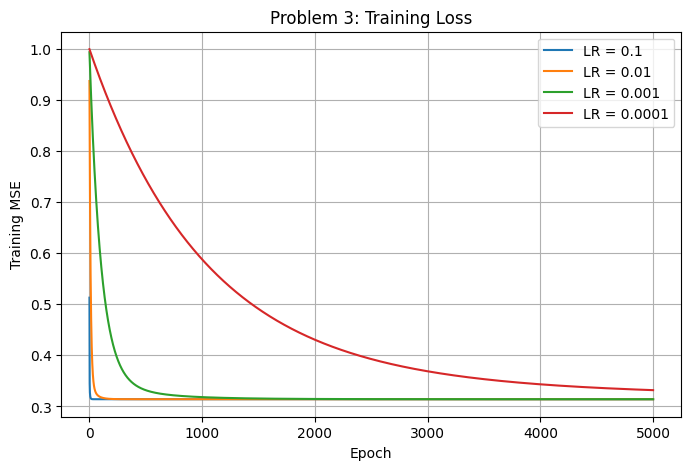

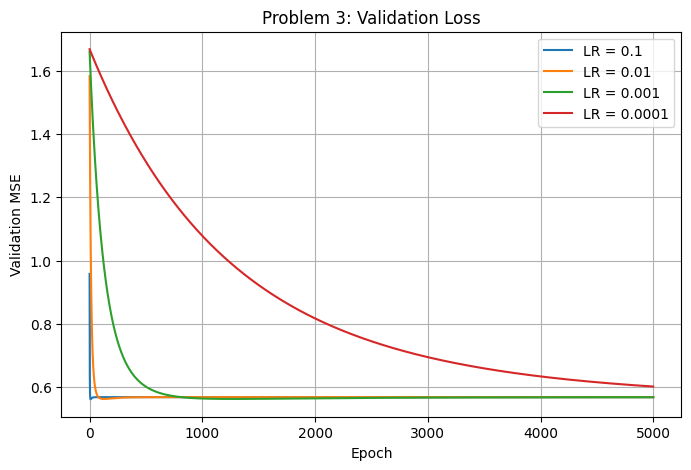

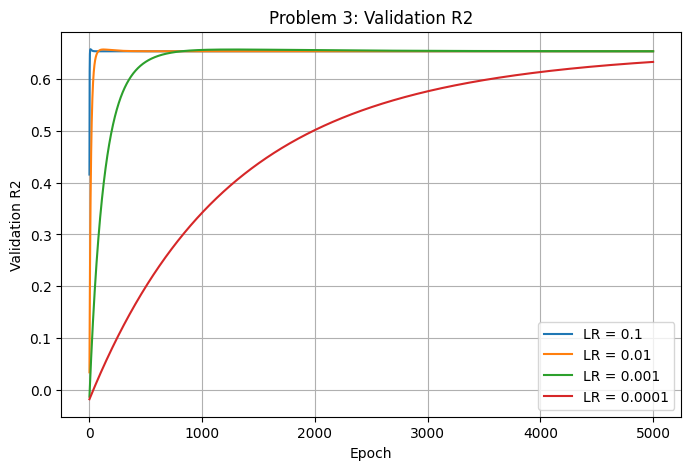


* FINAL VALIDATION RESULTS
MSE: 1753726390409.83
RMSE: 1324283.35
R2: 0.653


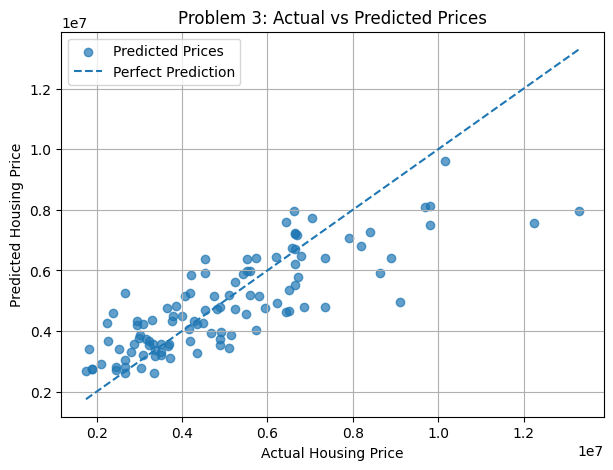


* PROBLEM 3 SUMMARY
 Learning Rate  Training Loss  Validation Loss  Validation R2
        0.1000       0.314056         0.568957       0.652924
        0.0100       0.314056         0.568957       0.652924
        0.0010       0.314058         0.568765       0.653041
        0.0001       0.331816         0.602480       0.632475


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("Housing.csv")

print("\nFirst five rows:")
print(df.head())

print("\nDataset Shape:", df.shape)


# Convert yes/no values to numbers
yes_no_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for col in yes_no_columns:
    df[col] = df[col].map({"yes": 1, "no": 0})


# Convert furnishing status using one-hot encoding
df = pd.get_dummies(
    df,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=int
)


# Select all input features
feature_names = [col for col in df.columns if col != "price"]

X = df[feature_names].values.astype(float)
y = df["price"].values.astype(float)

print("\nFeatures:")
print(feature_names)

print("\nNumber of Features:", X.shape[1])


# Split dataset: 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples:", len(y_train))
print("Validation Samples:", len(y_val))


# Normalize using training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_std[X_std == 0] = 1

y_mean = y_train.mean()
y_std = y_train.std()

X_train_scaled = (X_train - X_mean) / X_std
X_val_scaled = (X_val - X_mean) / X_std

y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled = (y_val - y_mean) / y_std

# LINEAR REGRESSION TRAINING LOOP
def train_model(X_train, y_train, X_val, y_val,
                learning_rate, epochs=5000):

    # Initialize weights and bias
    w = np.zeros(X_train.shape[1])
    b = 0.0

    train_losses = []
    val_losses = []
    val_r2_scores = []

    for epoch in range(1, epochs + 1):

        # Forward pass
        prediction = X_train @ w + b

        # Calculate error
        error = prediction - y_train

        # Calculate gradients
        grad_w = (2 / len(y_train)) * (X_train.T @ error)
        grad_b = 2 * np.mean(error)

        # Update parameters
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

        # Training loss
        train_pred = X_train @ w + b
        train_loss = np.mean((train_pred - y_train)**2)

        # Validation loss and R2
        val_pred = X_val @ w + b

        val_loss = np.mean((val_pred - y_val)**2)
        val_r2 = r2_score(y_val, val_pred)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_r2_scores.append(val_r2)

        # Print every 500 epochs
        if epoch % 500 == 0:
            print(
                f"Epoch {epoch:4d} | "
                f"Train Loss = {train_loss:.6f} | "
                f"Val Loss = {val_loss:.6f} | "
                f"Val R2 = {val_r2:.4f}"
            )

    return w, b, train_losses, val_losses, val_r2_scores

# 3.b TRAIN USING FOUR LEARNING RATES
learning_rates = [0.1, 0.01, 0.001, 0.0001]

results = {}

for lr in learning_rates:

    print(f"\n* Learning Rate: {lr}")

    w, b, train_loss, val_loss, val_r2 = train_model(
        X_train_scaled,
        y_train_scaled,
        X_val_scaled,
        y_val_scaled,
        learning_rate=lr,
        epochs=5000
    )

    results[lr] = {
        "w": w,
        "b": b,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_r2": val_r2
    }

    print("\nFinal Parameters:")
    print("Weights:", w)
    print("Bias:", b)

    print("Final Training Loss:", train_loss[-1])
    print("Final Validation Loss:", val_loss[-1])
    print("Final Validation R2:", val_r2[-1])

# FIND BEST MODEL
best_lr = min(
    learning_rates,
    key=lambda lr: results[lr]["val_loss"][-1]
)

best_model = results[best_lr]

print("\n* BEST MODEL")

print("Best Learning Rate:", best_lr)
print("Best Validation Loss:", best_model["val_loss"][-1])
print("Best Validation R2:", best_model["val_r2"][-1])


# Convert parameters to original units
w_original = y_std * best_model["w"] / X_std

b_original = (
    y_mean
    + y_std * best_model["b"]
    - np.sum(w_original * X_mean)
)

print("\n* Best Model Parameters (Original Units)")

for feature, weight in zip(feature_names, w_original):
    print(f"{feature}: {weight:.4f}")

print(f"Bias: {b_original:.4f}")

# PLOT TRAINING LOSS FOR FOUR LEARNING RATES
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        results[lr]["train_loss"],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Problem 3: Training Loss")
plt.legend()
plt.grid()
plt.show()

# PLOT VALIDATION LOSS FOR FOUR LEARNING RATES

plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        results[lr]["val_loss"],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Problem 3: Validation Loss")
plt.legend()
plt.grid()
plt.show()

# PLOT VALIDATION R2 FOR FOUR LEARNING RATES

plt.figure(figsize=(8, 5))

for lr in learning_rates:
    plt.plot(
        results[lr]["val_r2"],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation R2")
plt.title("Problem 3: Validation R2")
plt.legend()
plt.grid()
plt.show()

# ACTUAL VS PREDICTED HOUSING PRICES
# Predictions using best model
pred_scaled = (
    X_val_scaled @ best_model["w"]
    + best_model["b"]
)

# Convert predictions back to actual prices
pred_actual = pred_scaled * y_std + y_mean

# Calculate evaluation metrics
mse = mean_squared_error(y_val, pred_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, pred_actual)

print("\n* FINAL VALIDATION RESULTS")

print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2:", round(r2, 4))


# Plot actual vs predicted
plt.figure(figsize=(7, 5))

plt.scatter(
    y_val,
    pred_actual,
    alpha=0.7,
    label="Predicted Prices"
)

minimum = min(y_val.min(), pred_actual.min())
maximum = max(y_val.max(), pred_actual.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Problem 3: Actual vs Predicted Prices")
plt.legend()
plt.grid()
plt.show()

summary = pd.DataFrame({
    "Learning Rate": learning_rates,
    "Training Loss": [
        results[lr]["train_loss"][-1]
        for lr in learning_rates
    ],
    "Validation Loss": [
        results[lr]["val_loss"][-1]
        for lr in learning_rates
    ],
    "Validation R2": [
        results[lr]["val_r2"][-1]
        for lr in learning_rates
    ]
})

print("\n* PROBLEM 3 SUMMARY")
print(summary.to_string(index=False))
